# Intro

Hello to my first jupyter notebook machine learning exercise.

Lets first load the basic's. 
The exlamation mark makes you run a command in shell. Below is for **colab**.
`! [ -e /content] && pip install -Uqq fastbook`


In [36]:
import multiprocessing as mp
mp.set_start_method('fork', force=True)
from fastai.vision.widgets import *
from fastai.vision.all import *


In [37]:
from ddgs import DDGS
from fastcore.all import *

def search_images(term, max_images=300):
    print(f"Searching for '(term)'")
    with DDGS() as ddgs:
        results = ddgs.images(query=term, max_results=max_images)
        image_urls = [r["image"] for r in results]
    return L(image_urls)


In [38]:
mushroom_types = 'Amanita phalloides','Amanita muscaria','Russula xerampelina'

path = Path('mushrooms')
if not path.exists():
    path.mkdir()
    for o in mushroom_types:
        dest =(path/o)
        dest.mkdir(exist_ok=True)
        results = search_images(f'{o} mushroom')
        download_images(dest,urls=results)



Now lets indentify the top 3 most dangerous mushrooms. First we search the images

In [39]:
fns = get_image_files(path)
fns

[Path('mushrooms/Amanita phalloides/62f921ec-543f-40fa-aba6-d9bee5ba1ef9.jpg'), Path('mushrooms/Amanita phalloides/138a88a0-2bc0-4f93-918b-4394a828c669.jpg'), Path('mushrooms/Amanita phalloides/49471ca8-c68c-44b5-9526-0d64dd633bbd.jpg'), Path('mushrooms/Amanita phalloides/c360b394-7a6e-41b3-947e-ec796a0d1307.jpg'), Path('mushrooms/Amanita phalloides/f7648719-4411-4636-abc4-7cae5d965f02.jpg'), Path('mushrooms/Amanita phalloides/861d06b0-ca09-4d76-97de-ac72270f212d.jpg'), Path('mushrooms/Amanita phalloides/171c1c87-1c5a-4c82-bfc4-584ba76ccdc2.JPG'), Path('mushrooms/Amanita phalloides/b79ede84-d729-4a43-bfe8-e8b6985d5aeb.jpg'), Path('mushrooms/Amanita phalloides/d649a6d5-d097-4dbd-8817-dc6768287a66.jpg'), Path('mushrooms/Amanita phalloides/5848aa5b-c5c3-485b-9803-36abacb7da56.jpg'), Path('mushrooms/Amanita phalloides/258373d0-8c95-479a-9c1d-ebad76903db1.jpg'), Path('mushrooms/Amanita phalloides/023437f5-af38-42bd-830f-9684a55f43e1.jpg'), Path('mushrooms/Amanita phalloides/6ab67a4b-93fe-4b

In [40]:
failed = verify_images(fns)
failed

[]

In [41]:
failed.map(Path.unlink)

[]

In [42]:
verify_images(fns)


[]

In [43]:
class DataLoaders(GetAttr):
    def __init__(self, *loaders): self.loaders=loaders
    def __getitem__(self,i): return self.loaders[i]
    train,valid = add_props(lambda i,self: self[i])

In [44]:
mushrooms = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=RandomResizedCrop(128, min_scale=(0.3))
    )

In [45]:
dls = mushrooms.dataloaders(path)

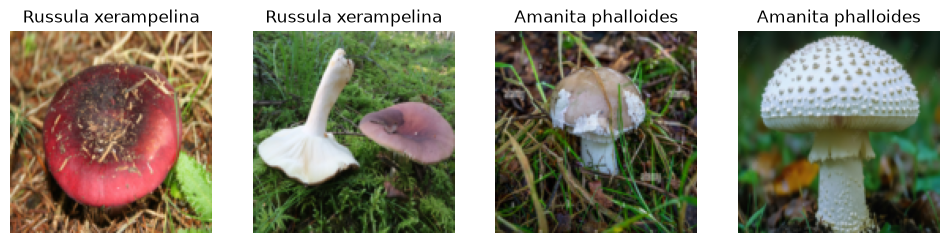

In [46]:
dls.valid.show_batch(max_n=4, nrows=1)


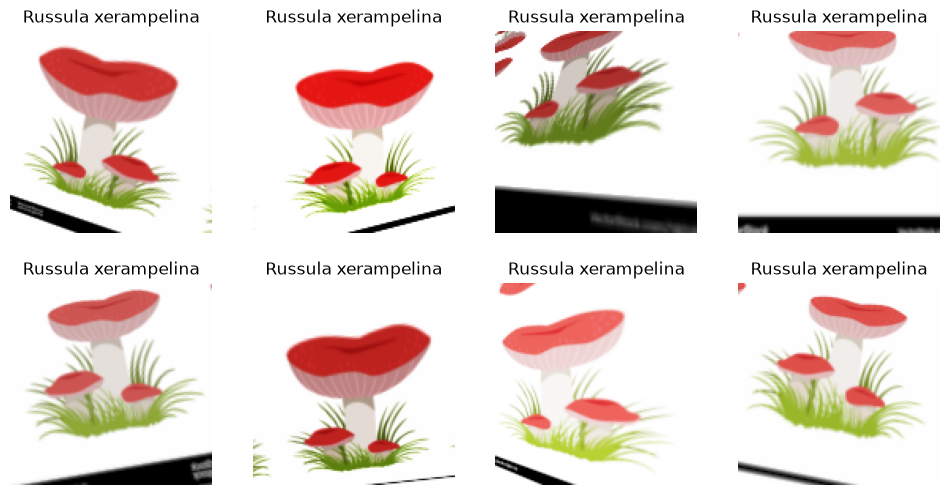

In [47]:
mushrooms = mushrooms.new(item_tfms=Resize(128), batch_tfms=aug_transforms(mult=2))
dls = mushrooms.dataloaders(path)
dls.train.show_batch(max_n=8, nrows=2, unique=True)


In [48]:
mushroomsbookmushrooms = mushrooms.new(
    item_tfms=RandomResizedCrop(224, min_scale=0.5),
    batch_tfms=aug_transforms())
dls = mushrooms.dataloaders(path, num_workers=0)
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(4)


epoch,train_loss,valid_loss,error_rate,time
0,1.520058,3.233380,0.684211,00:06


epoch,train_loss,valid_loss,error_rate,time
0,1.588585,2.587666,0.631579,00:08
1,1.530482,1.635824,0.473684,00:08
2,1.283108,1.132928,0.368421,00:08
3,1.061370,0.894320,0.368421,00:06


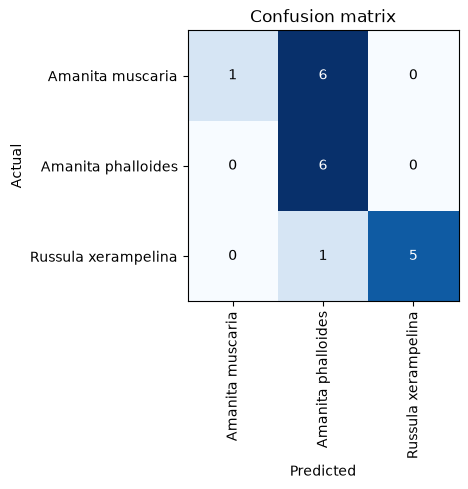

In [49]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

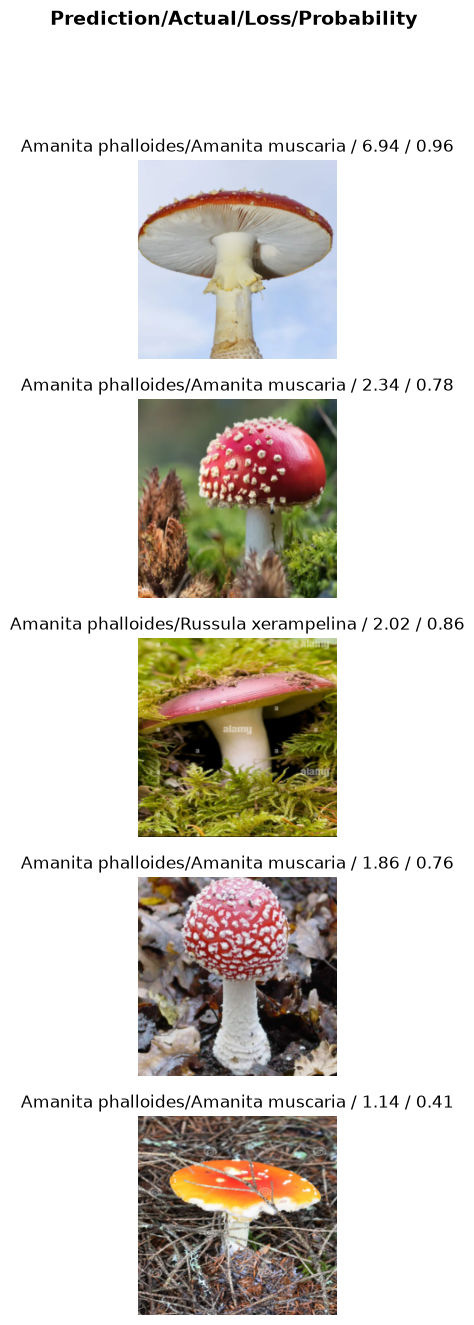

In [50]:
interp.plot_top_losses(5, nrows=5)


In [51]:
cleaner =  ImageClassifierCleaner(learn)
cleaner

In [52]:
for idx in cleaner.delete(): cleaner.fns[idx].unlink()

In [53]:
for idx,cat in cleaner.change(): shutil.move(str(cleaner.fns[idx]), path/cat)

In [54]:
learn.export()

In [55]:
path = Path()
path.ls(file_exts='.pkl')

[Path('export.pkl')]

In [56]:
learn_inf=load_learner(path/'export.pkl')
learn_inf.predict(fns[0])

/home/mausz/code/fastai/.venv/lib/python3.14/site-packages/fastai/learner.py:456: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


('Amanita phalloides', tensor(1), tensor([2.4990e-05, 9.9518e-01, 4.7922e-03]))

In [57]:
learn_inf.dls.vocab

['Amanita muscaria', 'Amanita phalloides', 'Russula xerampelina']

In [58]:
#hide output
btn_upload = widgets.FileUpload()
btn_upload

FileUpload(value={}, description='Upload')

In [59]:
btn_upload = SimpleNamespace(data = ['/home/mausz/code/fastai/mushroomsbook/mushrooms/Amanita muscaria/46585c39-1c3b-4080-9cf9-afddac9c7851.jpg'])

In [60]:
img= PILImage.create(btn_upload.data[-1])

In [61]:
out_pl = widgets.Output()
out_pl.clear_output()
with out_pl: display(img.to_thumb(128,128))
out_pl

Output()

In [62]:
pred,pred_idx,probs = learn_inf.predict(img)

In [63]:
lbl_pred = widgets.Label()
lbl_pred.value = f'Prediction: {pred}; Probality: {probs[pred_idx]:.04f}'
lbl_pred

Label(value='Prediction: Amanita phalloides; Probality: 0.9596')

In [64]:
btn_run = widgets.Button(description='Classify')
btn_run

Button(description='Classify', style=ButtonStyle())

In [65]:
def on_click_classify(change):
    img = PILImage.create(btn_upload.data[-1])
    out_pl.clear_output()
    with out_pl: display(img.to_thumb(128,128))
    pred,pred_idx,probs = learn_inf.predict(img)
    lbl_pred.value = f'Prediction: {pred}; Probability: {probs[pred_idx]:.04f}'

btn_run.on_click(on_click_classify)

In [66]:
btn_upload = widgets.FileUpload()

In [67]:
VBox([widgets.Label('Select you mushroom'),
      btn_upload,btn_run,out_pl,lbl_pred])

In [68]:
%pip install voila
!jupyter server extension enable --sys-prefix voila.server_extension



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Enabling: voila.server_extension
- Writing config: /home/mausz/code/fastai/.venv/etc/jupyter
    - Validating voila.server_extension...
      voila.server_extension  OK
    - Extension successfully enabled.


In [69]:
import sys; print(sys.executable)
!which pip jupyter

/home/mausz/code/fastai/.venv/bin/python
/home/mausz/code/fastai/.venv/bin/pip
/home/mausz/code/fastai/.venv/bin/jupyter


In [70]:
!head -1 /home/mausz/code/fastai/.venv/bin/jupyter
!python -c "import voila, importlib; [importlib.import_module(p['module']) for p in voila._jupyter_server_extension_points()]"

#!/home/mausz/code/fastai/.venv/bin/python3
Traceback (most recent call last):
  File "<string>", line 1, in <module>
    import voila, importlib; [importlib.import_module(p['module']) for p in voila._jupyter_server_extension_points()]
                                                                            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: module 'voila' has no attribute '_jupyter_server_extension_points'
